# Large scale ambiguity exploration

Trying to replicate the issue of having large scale ambiguities along a runway trajectory.
Running a basic test with satellite image correlations

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from scipy.ndimage import map_coordinates

Image (H, W): (1373, 2193)


Text(0.5, 1.0, 'Satellite Map')

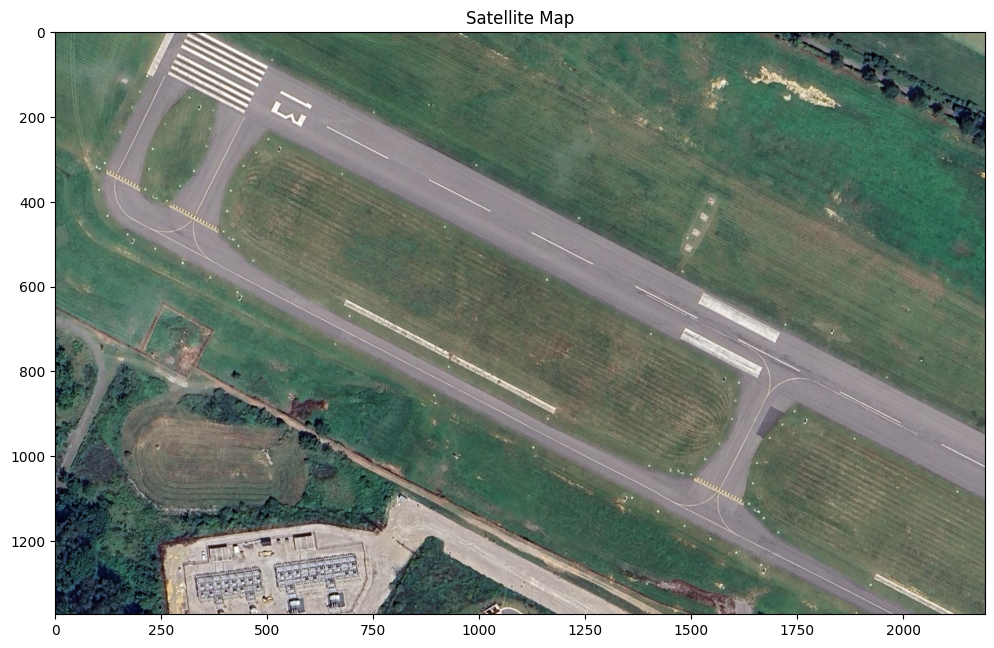

In [2]:
# Satellite reference image
# sat_ref = "../../datasets/KBCB_satellite/KBCB_partial.jpg" # Public google earth satellite imagery
sat_ref = "../../datasets/KBCB_satellite/KBCB_partial_LSA.png"

sat_rgb = cv2.cvtColor(cv2.imread(sat_ref), cv2.COLOR_BGR2RGB)
H, W = sat_rgb.shape[:2]
print("Image (H, W):", (H,W))

plt.figure(figsize=(12, 8))
plt.imshow(sat_rgb)
plt.title("Satellite Map")

## Trapezoid gridding

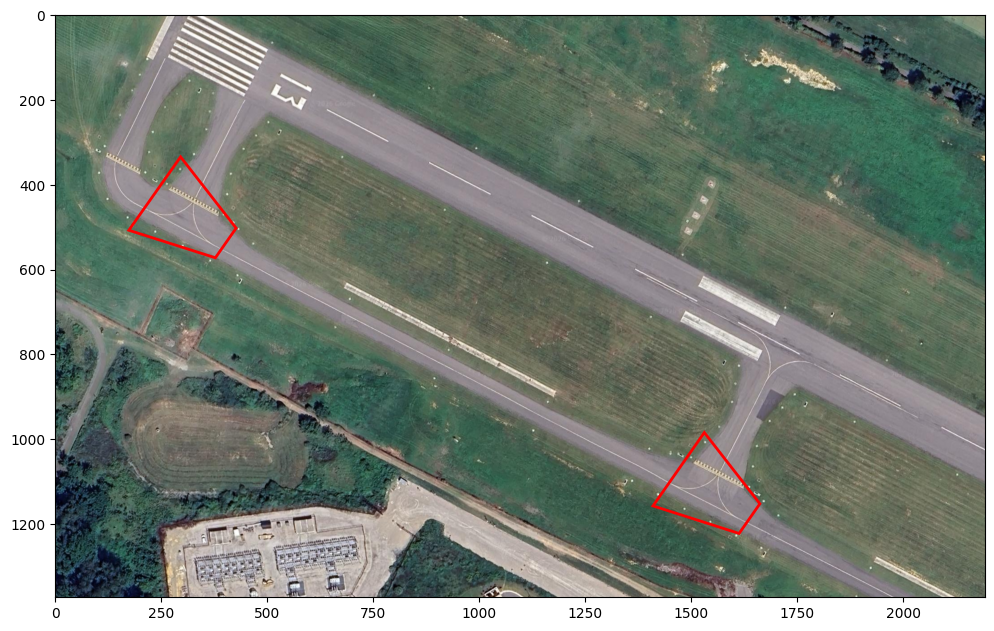

In [3]:
# Define trapezoid sections to test
# Corners (x, y): [far-left, far-right, near-right, near-left], picked by eye, heading ~215 deg (up-left)

traps = [np.array([[174, 507], [296, 334], [427, 502], [378, 572]]),          # top-left intersection
         np.array([[1410, 1157], [1531, 984], [1662, 1152], [1613, 1222]])]   # right intersection

names = ['P1']

plt.figure(figsize=(12, 8))
plt.imshow(sat_rgb)
for q in traps:
    plt.gca().add_patch(plt.Polygon(q, fill=False, ec='r', lw=2))

## Initial SSDs

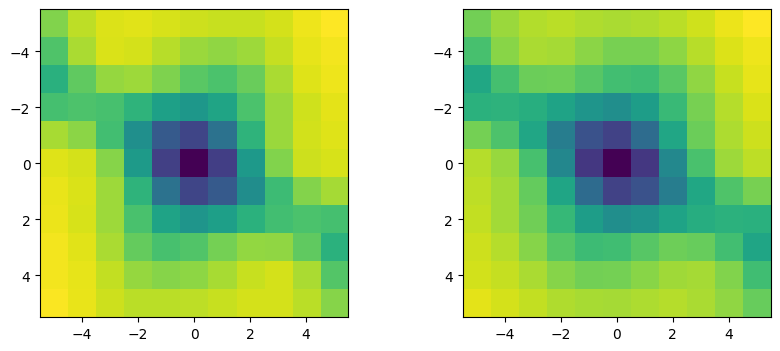

In [4]:
# Correlation process for satellite image maps

sat_g = cv2.cvtColor(sat_rgb, cv2.COLOR_RGB2GRAY).astype(np.float32) / 255
n = 5

ssds_all = []
for q in traps:
    mask = np.zeros((H,W), np.uint8)
    cv2.fillPoly(mask, [q.astype(np.int32)], 1)
    ys, xs = np.nonzero(mask) # Pixels inside the trapezoid
    tmpl = sat_g[ys, xs]

    # SSDs
    ssds = np.zeros((2*n+1, 2*n+1))
    for shiftx in range(-n, n+1):
        for shifty in range(-n, n+1):
            diffs = tmpl - sat_g[ys + shifty, xs + shiftx]
            ssds[shiftx + n, shifty + n] = np.sum(diffs**2)
    ssds_all.append(ssds)

fig, axs = plt.subplots(1, len(ssds_all), figsize=(10,4))
for i, (a,s) in enumerate(zip(axs, ssds_all)):
    im = a.imshow(s.T, extent=[-n-.5, n+.5, n+.5, -n-.5])


In [5]:
x = np.linspace(-n, n, 2*n + 1)
Y, X = np.meshgrid(x, x)  # ssds indexed [shiftx + n, shifty + n]

for i, ssds in enumerate(ssds_all):
    fig = go.Figure()
    fig.add_surface(x=X, y=Y, z=ssds, colorscale='Viridis', colorbar=dict(title='SSD'))
    fig.update_layout(
        title=f'SSD Surface Plot: P{i+1}',
        scene=dict(xaxis=dict(title='X Shift (pixels)'),
                   yaxis=dict(title='Y Shift (pixels)'),
                   zaxis=dict(title='SSD'),
                   aspectmode='cube'),
        width=900, height=800)
    fig.show()

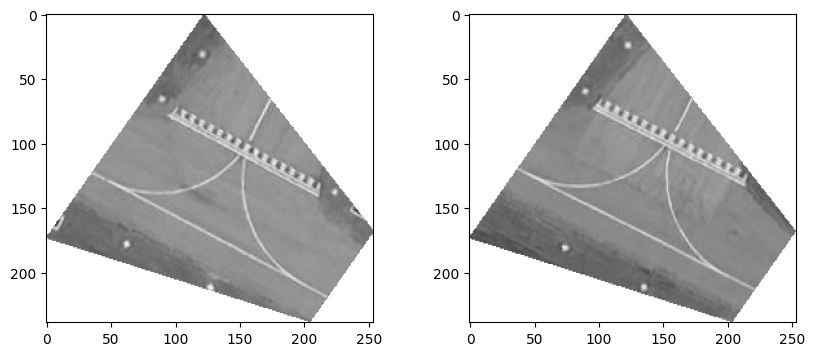

In [6]:
fig, axs = plt.subplots(1, len(traps), figsize=(10,4))

# for q in traps:
for i, (a,q) in enumerate(zip(axs, traps)):
    mask = np.zeros((H,W), np.uint8)
    cv2.fillPoly(mask, [q.astype(np.int32)], 1)
    ys, xs = np.nonzero(mask) # Pixels inside the trapezoid
    tmpl_img = np.full((H,W), np.nan)
    tmpl = sat_g[ys, xs]
    tmpl_img[ys, xs] = tmpl
    a.imshow(tmpl_img[ys.min():ys.max()+1, xs.min():xs.max()+1], cmap='gray', vmin=0, vmax=1)


## Cross alignment (creating the ambiguity)

In [7]:
# Final transforms for P1 and P2
# tforms = [[1238, 644, -.75],[-1238,-644,0.75]]

In [8]:
def create_tform(tx, ty, theta):
    """
    Create transformation matrix for 2D image matching 
    """
    th_r = np.deg2rad(theta)
    T = np.array([[np.cos(th_r), -np.sin(th_r), tx],
                  [np.sin(th_r), np.cos(th_r), ty],
                  [0, 0, 1]])
    return T

[[ 9.99914328e-01 -1.30895956e-02  0.00000000e+00]
 [ 1.30895956e-02  9.99914328e-01  0.00000000e+00]
 [ 1.23176066e+03  6.48213324e+02  1.00000000e+00]]


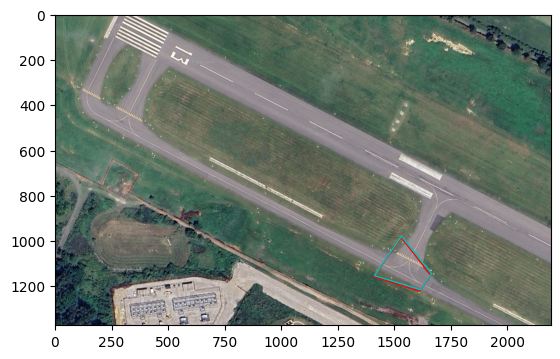

In [13]:
# WHICH SECTION 
s = 0 # 0 is P1, 1 is P2
s_0 = 1 if s == 0 else 0

# Align P1 with P2, and align P2 with P1 
# Test P1
tx = 1238 #1236
ty = 644 #650
theta = -0.75

# Rotate about P1 centroid: shift centroid to origin -> rotate -> shift back -> translate by (tx, ty)
pivot = traps[s].mean(axis=0)
T = create_tform(tx, ty, 0) @ create_tform(*pivot, theta) @ create_tform(*-pivot, 0)
print(T.T)

# Re-align points 
c = np.hstack([traps[s], np.ones((4,1))]) # homogeneous
pts_check = c @ T.T


plt.imshow(sat_rgb)
plt.gca().add_patch(plt.Polygon(traps[s_0], fill=False, ec='r'))
plt.gca().add_patch(plt.Polygon(pts_check[:, :2], fill=False, ec='c'))


In [14]:
# Open3d alignment visualization 
import open3d as o3d

# Satellite map as grayscale point cloud (x, y, 0) in pixel units
yy, xx = np.mgrid[0:H, 0:W]
ref_pts = np.column_stack([xx.ravel(), yy.ravel(), np.zeros(H*W)])
ref_pts[0, 2] = 1   # lift one corner pixel so the bbox isn't flat (Open3D treats zero-volume bbox as empty -> zoom changes)
ref_cloud = o3d.geometry.PointCloud()
ref_cloud.points = o3d.utility.Vector3dVector(ref_pts)
ref_cloud.colors = o3d.utility.Vector3dVector(np.repeat(sat_g.reshape(-1, 1), 3, axis=1))

# P1 pixels moved by T
mask = np.zeros((H, W), np.uint8)
cv2.fillPoly(mask, [traps[s].astype(np.int32)], 1)
ys, xs = np.nonzero(mask)
p_moved = np.column_stack([xs, ys, np.ones(len(xs))]) @ T.T   # homogeneous, N x 3

p_cloud = o3d.geometry.PointCloud()
p_cloud.points = o3d.utility.Vector3dVector(np.column_stack([p_moved[:, :2], -np.ones(len(xs))]))  # z=-1 to sit on top of map
p_cloud.colors = o3d.utility.Vector3dVector(np.repeat(sat_g[ys, xs].reshape(-1, 1), 3, axis=1))# * [0.6, 1.0, 1.0])  # cyan tint

# P2 outline for reference
p_i_outline = o3d.geometry.LineSet()
p_i_outline.points = o3d.utility.Vector3dVector(np.column_stack([traps[s_0], -2 * np.ones(4)]))
p_i_outline.lines = o3d.utility.Vector2iVector([[0, 1], [1, 2], [2, 3], [3, 0]])
p_i_outline.colors = o3d.utility.Vector3dVector([[1, 0, 0]] * 4)

# Fixed start view: top-down on the moved patch, image orientation (x right, y down)
o3d.visualization.draw_geometries([ref_cloud, p_cloud], window_name="P1 -> P2 alignment", # , p_i_outline
                                  lookat=[*p_moved[:, :2].mean(axis=0), 0],
                                  front=[0, 0, -1],   # camera on -z side (overlay side)
                                  up=[0, -1, 0],
                                  zoom=0.07)   # relative to full map extent (~2190 px)


## Cross SSD 

In [15]:
# SSD: P1 template sampled on P2's section through T (bilinear for sub-pixel coords)

mask = np.zeros((H, W), np.uint8)
cv2.fillPoly(mask, [traps[s].astype(np.int32)], 1)
ys, xs = np.nonzero(mask)
tmpl = sat_g[ys, xs]

q = (np.column_stack([xs, ys, np.ones(len(xs))]) @ T.T)[:, :2]   # P1 pixels mapped into P2 (float x, y)

ssd_curr = np.zeros((2*n+1, 2*n+1))
for shiftx in range(-n, n+1):
    for shifty in range(-n, n+1):
        vals = map_coordinates(sat_g, [q[:, 1] + shifty, q[:, 0] + shiftx], order=1)   # [rows, cols] = [y, x]
        ssd_curr[shiftx + n, shifty + n] = np.sum((tmpl - vals)**2)


In [16]:
i, j = s+1, s_0+1
fig = go.Figure()
fig.add_surface(x=X, y=Y, z=ssd_curr, colorscale='Viridis', colorbar=dict(title='SSD'))
fig.update_layout(
    title=f'SSD Surface Plot: P{i} on P{j}',
    scene=dict(xaxis=dict(title='X Shift (pixels)'),
                yaxis=dict(title='Y Shift (pixels)'),
                zaxis=dict(title='SSD'),
                aspectmode='cube'),
    width=900, height=800)
fig.show()

In [ ]:
# MINIMUM SHIFT PT

idrow, idcol = np.unravel_index(np.argmin(ssd_curr), ssd_curr.shape)
shiftx_min, shifty_min = idrow - n, idcol - n

print(shiftx_min, shifty_min)
